# HPO Plots

Loads HPO-B BO evaluation artifacts from `notebooks/final_results/hpob/<search_space>/<method>/`.

Each method directory should contain `metadata.json` plus metric arrays such as `regret.npy` and `normalized_regret.npy` exported by `scripts/evaluate_bo.py`.


In [8]:
from pathlib import Path
import json
import warnings
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

%load_ext autoreload
%autoreload 2


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() or (candidate / ".git").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_ROOT = REPO_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from polar.utils.plotting import PAPER_COLORS, apply_style  # noqa: E402

apply_style(use_tex=False, base_font_size=20)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
METHOD_COLORS = {
    "POLAR": PAPER_COLORS[1],
    "GP": PAPER_COLORS[0],
    "Random": PAPER_COLORS[6],
    "NAP": PAPER_COLORS[2],
    "PFNs4BO": PAPER_COLORS[3],
    "Meta-GP": PAPER_COLORS[4],
    "TabICL": PAPER_COLORS[5],
}
METHOD_MARKERS = {
    "POLAR": "*",
    "GP": "o",
    "Random": "^",
    "NAP": "s",
    "PFNs4BO": "D",
    "Meta-GP": "P",
    "TabICL": "X",
}


def load_hpob_method_artifact(path: Path | str, metric: str = "regret") -> dict:
    method_dir = Path(path).expanduser().resolve()
    metadata_path = method_dir / "metadata.json"
    if not metadata_path.exists():
        raise FileNotFoundError(f"Missing metadata.json under {method_dir}")

    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    artifact_files = metadata.get("artifact_files", {})
    metric_file = artifact_files.get(metric, f"{metric}.npy")
    metric_path = method_dir / metric_file if not Path(metric_file).is_absolute() else Path(metric_file)
    if not metric_path.exists():
        raise FileNotFoundError(f"Missing {metric}.npy under {method_dir}")

    curves = np.load(metric_path)
    return {
        "method_dir": method_dir,
        "metadata": metadata,
        "metric": metric,
        "curves": curves,
        "rounds": np.asarray(metadata["rounds"], dtype=np.int64),
    }


def load_nap_result(
    path: Path | str,
    search_space_id: str,
    *,
    metric: str = "regret",
    reference_path: Path | str | None = None,
) -> dict:
    nap_path = Path(path).expanduser().resolve()
    payload = json.loads(nap_path.read_text(encoding="utf-8"))
    search_space_key = str(search_space_id)
    if search_space_key not in payload:
        available = ", ".join(sorted(payload.keys()))
        raise KeyError(f"search_space_id={search_space_key} not found in {nap_path.name}. Available: {available}")

    if metric not in {"regret", "normalized_regret"}:
        raise ValueError("JSON helper currently supports only regret and normalized_regret.")

    search_space_payload = payload[search_space_key]
    if metric == "regret" and reference_path is None:
        raise ValueError("load_nap_result(..., metric='regret') requires reference_path to recover the original regret scale.")

    if reference_path is not None:
        reference_regret = load_hpob_method_artifact(reference_path, metric="regret")
        reference_norm = load_hpob_method_artifact(reference_path, metric="normalized_regret")
        dataset_ids = list(reference_regret["metadata"]["dataset_ids"])
        seeds = list(reference_regret["metadata"]["seeds"])
        reference_rounds = np.asarray(reference_regret["rounds"], dtype=np.int64)
        ratio = np.divide(
            reference_regret["curves"],
            reference_norm["curves"],
            out=np.full_like(reference_regret["curves"], np.nan, dtype=np.float32),
            where=np.abs(reference_norm["curves"]) > 1e-12,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            range_scale = np.nanmedian(ratio, axis=2)
        range_scale = np.where(np.isfinite(range_scale), range_scale, 0.0).astype(np.float32)
        target_rounds = reference_rounds
        reference_round0 = (
            reference_regret["curves"][..., 0] if metric == "regret" else reference_norm["curves"][..., 0]
        ).astype(np.float32)
    else:
        dataset_ids = list(search_space_payload.keys())
        seeds = list(next(iter(search_space_payload.values())).keys())
        range_scale = None
        target_rounds = None

    n_rounds = len(next(iter(next(iter(search_space_payload.values())).values())))
    curves = np.full((len(dataset_ids), len(seeds), n_rounds), np.nan, dtype=np.float32)

    for dataset_idx, dataset_id in enumerate(dataset_ids):
        seed_map = search_space_payload.get(dataset_id)
        if seed_map is None:
            continue
        for seed_idx, seed in enumerate(seeds):
            values = seed_map.get(seed)
            if values is None:
                continue
            y_curve = np.asarray(values, dtype=np.float32)
            normalized_regret = np.clip(1.0 - y_curve, a_min=0.0, a_max=None)
            if metric == "normalized_regret":
                curves[dataset_idx, seed_idx, :] = normalized_regret
            else:
                scale = range_scale[dataset_idx, seed_idx]
                curves[dataset_idx, seed_idx, :] = normalized_regret * scale

    rounds = np.arange(n_rounds, dtype=np.int64)
    if target_rounds is not None:
        target_len = min(len(target_rounds), curves.shape[-1])
        curves = curves[..., :target_len]
        rounds = target_rounds[:target_len]
        if target_len > 0:
            curves[..., 0] = reference_round0

    metadata = {
        "method": nap_path.stem,
        "search_space_id": search_space_key,
        "dataset_ids": dataset_ids,
        "seeds": seeds,
        "rounds": rounds.tolist(),
        "array_shape": list(curves.shape),
        "source_path": str(nap_path),
        "source_format": nap_path.name,
        "curve_interpretation": "converted from normalized best-y to regret" if metric == "regret" else "1 - normalized best-y",
    }
    return {
        "method_dir": nap_path,
        "metadata": metadata,
        "metric": metric,
        "curves": curves,
        "rounds": rounds,
    }


def load_hpob_sources(
    sources: dict[str, Path | str | dict | None],
    *,
    metric: str = "regret",
) -> list[dict]:
    loaded = []
    for label, source in sources.items():
        if source is None:
            continue
        if isinstance(source, dict):
            artifact = source.copy()
        else:
            method_dir = Path(source)
            if not method_dir.exists():
                print(f"Skipping {label}: {method_dir} not found")
                continue
            artifact = load_hpob_method_artifact(method_dir, metric=metric)
        artifact["label"] = label
        loaded.append(artifact)

    if not loaded:
        raise ValueError("No HPO-B artifacts were loaded.")
    return loaded


def _trim_loaded_artifacts_to_common_rounds(loaded: list[dict]) -> tuple[list[dict], np.ndarray]:
    common_len = min(len(artifact["rounds"]) for artifact in loaded)
    rounds = np.asarray(loaded[0]["rounds"][:common_len], dtype=np.int64)
    trimmed = []
    for artifact in loaded:
        trimmed_artifact = artifact.copy()
        trimmed_artifact["rounds"] = np.asarray(artifact["rounds"][:common_len], dtype=np.int64)
        trimmed_artifact["curves"] = artifact["curves"][..., :common_len]
        trimmed.append(trimmed_artifact)
    return trimmed, rounds


def _mean_stderr_from_stack(stacked: np.ndarray) -> dict[str, np.ndarray]:
    counts = np.sum(~np.isnan(stacked), axis=0)
    means = np.nanmean(stacked, axis=0)
    stds = np.nanstd(stacked, axis=0)
    stderrs = np.divide(
        stds,
        np.sqrt(np.maximum(counts, 1)),
        out=np.zeros_like(stds),
        where=counts > 0,
    )
    return {
        "mean": means,
        "stderr": stderrs,
        "counts": counts,
    }


def aggregate_hpob_curves(curves: np.ndarray) -> dict[str, np.ndarray]:
    if curves.ndim != 3:
        raise ValueError(f"Expected curves with shape [n_datasets, n_seeds, n_rounds], got {curves.shape}")

    flat = curves.reshape(-1, curves.shape[-1])
    return _mean_stderr_from_stack(flat)


def _compute_log_floor(loaded: list[dict]) -> float:
    positive_values = []
    for artifact in loaded:
        positive_values.extend(artifact["aggregate"]["mean"][artifact["aggregate"]["mean"] > 0.0].tolist())
        positive_values.extend(artifact["aggregate"]["stderr"][artifact["aggregate"]["stderr"] > 0.0].tolist())
    return max(min(positive_values) * 0.1, 1e-12) if positive_values else 1e-12


def _average_rank(values: np.ndarray, *, rtol: float = 1e-4, atol: float = 1e-6) -> np.ndarray:
    values = np.asarray(values, dtype=np.float64)
    order = np.argsort(values)
    sorted_values = values[order]
    ranks = np.empty_like(sorted_values, dtype=np.float64)

    start = 0
    while start < len(sorted_values):
        end = start + 1
        while end < len(sorted_values) and np.isclose(sorted_values[end], sorted_values[start], rtol=rtol, atol=atol):
            end += 1
        avg_rank = 0.5 * (start + end - 1) + 1.0
        ranks[start:end] = avg_rank
        start = end

    output = np.empty_like(ranks)
    output[order] = ranks
    return output


def aggregate_rank_curves(method_curves: np.ndarray) -> dict[str, np.ndarray]:
    if method_curves.ndim != 4:
        raise ValueError(
            f"Expected method_curves with shape [n_methods, n_datasets, n_seeds, n_rounds], got {method_curves.shape}"
        )

    n_methods, _, _, n_rounds = method_curves.shape
    means = np.full((n_methods, n_rounds), np.nan, dtype=np.float64)
    stderrs = np.zeros((n_methods, n_rounds), dtype=np.float64)
    counts = np.zeros(n_rounds, dtype=np.int64)

    for step in range(n_rounds):
        step_values = method_curves[:, :, :, step].reshape(n_methods, -1)
        valid_cols = np.all(np.isfinite(step_values), axis=0)
        if not np.any(valid_cols):
            continue
        valid_values = step_values[:, valid_cols]
        step_ranks = np.stack([_average_rank(valid_values[:, col]) for col in range(valid_values.shape[1])], axis=1)
        means[:, step] = np.mean(step_ranks, axis=1)
        stds = np.std(step_ranks, axis=1)
        stderrs[:, step] = stds / np.sqrt(max(step_ranks.shape[1], 1))
        counts[step] = step_ranks.shape[1]

    return {
        "mean": means,
        "stderr": stderrs,
        "counts": counts,
    }


def plot_hpob_curve_block(
    sources: dict[str, Path | str | dict | None],
    *,
    metric: str = "regret",
    title: str | None = None,
    marker_every: int = 5,
    show_legend: bool = True,
    save_path: Path | str | None = None,
):
    loaded = load_hpob_sources(sources, metric=metric)
    loaded, _ = _trim_loaded_artifacts_to_common_rounds(loaded)
    for artifact in loaded:
        artifact["aggregate"] = aggregate_hpob_curves(artifact["curves"])

    if title is None:
        search_space_id = loaded[0]["metadata"].get("search_space_id", "")
        title = f"Search space No. {search_space_id}" if search_space_id else "HPO-B"

    log_floor = _compute_log_floor(loaded)

    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    for method_idx, artifact in enumerate(loaded):
        label = artifact["label"]
        rounds = artifact["rounds"]
        means = np.maximum(artifact["aggregate"]["mean"], log_floor)
        stderrs = artifact["aggregate"]["stderr"]
        lower = np.maximum(means - stderrs, log_floor)
        upper = np.maximum(means + stderrs, log_floor)

        color = METHOD_COLORS.get(label, PAPER_COLORS[method_idx % len(PAPER_COLORS)])
        marker = METHOD_MARKERS.get(label, "o")
        markersize = 15 if marker == "*" else 9
        markevery = list(range(0, len(rounds), marker_every)) if marker_every > 0 else None

        ax.plot(
            rounds,
            means,
            color=color,
            linewidth=2.5,
            drawstyle="steps-post",
            marker=marker,
            markersize=markersize,
            markeredgewidth=1.2 if marker == "*" else 1.0,
            markevery=markevery,
            label=label,
        )
        ax.fill_between(rounds, lower, upper, color=color, alpha=0.14, step="post")

    y_label = "Regret" if metric == "regret" else "Normalized Regret"
    ax.set_title(title)
    ax.set_xlabel("Step (acquisition round)")
    ax.set_ylabel(y_label)
    ax.set_yscale("log")
    ax.set_ylim(bottom=log_floor)
    ax.grid(alpha=0.25)
    if show_legend:
        ax.legend(loc="lower left")

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, ax


def build_multi_space_summary(
    search_space_ids: list[str] | tuple[str, ...],
    source_builder,
    *,
    metric: str = "normalized_regret",
) -> dict:
    if not search_space_ids:
        raise ValueError("search_space_ids must be non-empty.")

    per_space_loaded: list[tuple[str, list[dict]]] = []
    for search_space_id in search_space_ids:
        try:
            loaded = load_hpob_sources(source_builder(str(search_space_id), metric=metric), metric=metric)
        except FileNotFoundError as exc:
            print(f"Skipping search space {search_space_id}: {exc}")
            continue
        loaded, _ = _trim_loaded_artifacts_to_common_rounds(loaded)
        per_space_loaded.append((str(search_space_id), loaded))

    if not per_space_loaded:
        raise ValueError("No search spaces could be loaded for the requested summary.")

    common_methods = [artifact["label"] for artifact in per_space_loaded[0][1]]
    for _, loaded in per_space_loaded[1:]:
        labels = {artifact["label"] for artifact in loaded}
        common_methods = [label for label in common_methods if label in labels]
    if not common_methods:
        raise ValueError("No common methods were found across the selected search spaces.")

    common_len = min(
        len(next(artifact for artifact in loaded if artifact["label"] == label)["rounds"])
        for _, loaded in per_space_loaded
        for label in common_methods
    )
    rounds = np.asarray(per_space_loaded[0][1][0]["rounds"][:common_len], dtype=np.int64)

    curve_stacks = {label: [] for label in common_methods}
    rank_curve_stacks = {label: [] for label in common_methods}
    for _, loaded in per_space_loaded:
        artifact_map = {artifact["label"]: artifact for artifact in loaded}
        method_curve_stack = np.stack(
            [artifact_map[label]["curves"][..., :common_len] for label in common_methods],
            axis=0,
        )
        rank_stats = aggregate_rank_curves(method_curve_stack)
        for method_idx, label in enumerate(common_methods):
            curve_stacks[label].append(aggregate_hpob_curves(method_curve_stack[method_idx])["mean"])
            rank_curve_stacks[label].append(rank_stats["mean"][method_idx])

    curve_summary = {}
    for label, curves in curve_stacks.items():
        stacked = np.stack(curves, axis=0)
        curve_summary[label] = _mean_stderr_from_stack(stacked)
        curve_summary[label]["per_space"] = stacked

    rank_summary = {}
    for label, rank_curves in rank_curve_stacks.items():
        method_ranks = np.stack(rank_curves, axis=0)
        rank_summary[label] = _mean_stderr_from_stack(method_ranks)
        rank_summary[label]["per_space"] = method_ranks

    return {
        "search_space_ids": [search_space_id for search_space_id, _ in per_space_loaded],
        "metric": metric,
        "rounds": rounds,
        "methods": common_methods,
        "curve_summary": curve_summary,
        "rank_summary": rank_summary,
    }


def plot_hpob_multi_space_summary(
    search_space_ids: list[str] | tuple[str, ...],
    source_builder,
    *,
    metric: str = "normalized_regret",
    title: str | None = None,
    marker_every: int = 8,
    show_legend: bool = True,
    save_path: Path | str | None = None,
):
    summary = build_multi_space_summary(search_space_ids, source_builder, metric=metric)
    rounds = summary["rounds"]
    methods = summary["methods"]

    left_loaded = []
    for label in methods:
        left_loaded.append({
            "label": label,
            "aggregate": summary["curve_summary"][label],
        })
    log_floor = _compute_log_floor(left_loaded)

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
    ax_curve, ax_rank = axes

    for method_idx, label in enumerate(methods):
        color = METHOD_COLORS.get(label, PAPER_COLORS[method_idx % len(PAPER_COLORS)])
        marker = METHOD_MARKERS.get(label, "o")
        markersize = 15 if marker == "*" else 9
        markevery = list(range(0, len(rounds), marker_every)) if marker_every > 0 else None

        curve_stats = summary["curve_summary"][label]
        curve_mean = np.maximum(curve_stats["mean"], log_floor)
        curve_stderr = curve_stats["stderr"]
        curve_lower = np.maximum(curve_mean - curve_stderr, log_floor)
        curve_upper = np.maximum(curve_mean + curve_stderr, log_floor)
        ax_curve.plot(
            rounds,
            curve_mean,
            color=color,
            linewidth=2.5,
            # drawstyle="steps-post",
            marker=marker,
            markersize=markersize,
            markeredgewidth=1.2 if marker == "*" else 1.0,
            markevery=markevery,
            label=label,
        )
        ax_curve.fill_between(rounds, curve_lower, curve_upper, color=color, alpha=0.14)

        rank_stats = summary["rank_summary"][label]
        rank_mean = rank_stats["mean"]
        rank_stderr = rank_stats["stderr"]
        ax_rank.plot(
            rounds,
            rank_mean,
            color=color,
            linewidth=2.5,
            # drawstyle="steps-post",
            marker=marker,
            markersize=markersize,
            markeredgewidth=1.2 if marker == "*" else 1.0,
            markevery=markevery,
            label=label,
        )
        ax_rank.fill_between(rounds, rank_mean - rank_stderr, rank_mean + rank_stderr, color=color, alpha=0.12)

    # if title is None:
    #     title = f"Average over {len(summary['search_space_ids'])} search spaces"
    # fig.suptitle(title, y=0.99, fontsize=20)

    # ax_curve.set_title("Normalized Regret", fontsize=15, pad=4)
    ax_curve.set_xlabel("Acquisition step")
    ax_curve.set_ylabel("Average Regret")
    ax_curve.set_yscale("log")
    curve_lower = min(
        float(np.nanmin(np.maximum(summary["curve_summary"][label]["mean"] - summary["curve_summary"][label]["stderr"], 1e-12)))
        for label in methods
    )
    curve_upper = max(float(np.nanmax(summary["curve_summary"][label]["mean"] + summary["curve_summary"][label]["stderr"])) for label in methods)
    ax_curve.set_ylim(max(curve_lower * 0.85, 1e-12), curve_upper * 1.05)
    ax_curve.grid(alpha=0.25)

    # ax_rank.set_title("Average Ranking", fontsize=15, pad=4)
    ax_rank.set_xlabel("Acquisition step")
    ax_rank.set_ylabel("Average Rank")
    # ax_rank.set_ylim(max(0.9, rank_lower - 0.12), min(len(methods) + 0.15, rank_upper + 0.12))
    # ax_rank.set_yticks(np.arange(1, len(methods) + 1))
    ax_rank.grid(alpha=0.25)

    fig.subplots_adjust(left=0.07, right=0.995, top=0.90, bottom=0.28, wspace=0.23)

    if show_legend:
        handles, labels = ax_curve.get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc="lower center",
            ncol=min(len(labels), 7),
            bbox_to_anchor=(0.5, 0.02),
            fontsize=18,
            handlelength=1.2,
            # handletextpad=0.4,
            # columnspacing=0.5,
            # labelspacing=0.1,
            # borderpad=0.2,
            frameon=True,
        )

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, axes, summary


def _prepare_hpob_search_space_panels(
    search_space_ids: list[str] | tuple[str, ...],
    source_builder,
    *,
    metric: str = "normalized_regret",
) -> tuple[list[tuple[str, list[dict]]], list[str]]:
    if not search_space_ids:
        raise ValueError("search_space_ids must be non-empty.")

    per_space_loaded: list[tuple[str, list[dict]]] = []
    for search_space_id in search_space_ids:
        try:
            loaded = load_hpob_sources(source_builder(str(search_space_id), metric=metric), metric=metric)
        except FileNotFoundError as exc:
            print(f"Skipping search space {search_space_id}: {exc}")
            continue
        loaded, _ = _trim_loaded_artifacts_to_common_rounds(loaded)
        per_space_loaded.append((str(search_space_id), loaded))

    if not per_space_loaded:
        raise ValueError("No search spaces could be loaded.")

    common_methods = [artifact["label"] for artifact in per_space_loaded[0][1]]
    for _, loaded in per_space_loaded[1:]:
        labels = {artifact["label"] for artifact in loaded}
        common_methods = [label for label in common_methods if label in labels]

    if not common_methods:
        raise ValueError("No common methods were found across the requested search spaces.")

    prepared: list[tuple[str, list[dict]]] = []
    for search_space_id, loaded in per_space_loaded:
        artifact_map = {artifact["label"]: artifact for artifact in loaded}
        common_len = min(len(artifact_map[label]["rounds"]) for label in common_methods)
        prepared_loaded: list[dict] = []
        for label in common_methods:
            artifact = artifact_map[label].copy()
            artifact["label"] = label
            artifact["rounds"] = np.asarray(artifact["rounds"][:common_len], dtype=np.int64)
            artifact["curves"] = artifact["curves"][..., :common_len]
            prepared_loaded.append(artifact)
        prepared.append((search_space_id, prepared_loaded))

    return prepared, common_methods


def plot_hpob_search_space_regret_grid(
    search_space_ids: list[str] | tuple[str, ...],
    source_builder,
    *,
    marker_every: int = 8,
    ncols: int = 3,
    show_legend: bool = True,
    save_path: Path | str | None = None,
):
    prepared, common_methods = _prepare_hpob_search_space_panels(
        search_space_ids,
        source_builder,
        metric="normalized_regret",
    )
    n_panels = len(prepared)
    ncols = max(1, int(ncols))
    nrows = int(np.ceil(n_panels / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4.15 * ncols, 3.6 * nrows), squeeze=False)
    flat_axes = axes.ravel()
    legend_handles = None
    legend_labels = None

    for panel_idx, ax in enumerate(flat_axes):
        if panel_idx >= n_panels:
            ax.axis("off")
            continue

        search_space_id, loaded = prepared[panel_idx]
        aggregated = []
        for artifact in loaded:
            aggregated.append(
                {
                    "label": artifact["label"],
                    "rounds": artifact["rounds"],
                    "aggregate": aggregate_hpob_curves(artifact["curves"]),
                }
            )

        lower_candidates = []
        for artifact in aggregated:
            lower_band = artifact["aggregate"]["mean"] - artifact["aggregate"]["stderr"]
            lower_candidates.extend(lower_band[lower_band > 0.0].tolist())
        panel_floor = max(min(lower_candidates) * 0.9, 1e-12) if lower_candidates else 1e-12
        curve_upper = max(
            float(np.nanmax(artifact["aggregate"]["mean"] + artifact["aggregate"]["stderr"]))
            for artifact in aggregated
        )

        for method_idx, artifact in enumerate(aggregated):
            label = artifact["label"]
            rounds = artifact["rounds"]
            means = np.maximum(artifact["aggregate"]["mean"], panel_floor)
            stderrs = artifact["aggregate"]["stderr"]
            lower = np.maximum(artifact["aggregate"]["mean"] - stderrs, panel_floor)
            upper = np.maximum(artifact["aggregate"]["mean"] + stderrs, panel_floor)
            color = METHOD_COLORS.get(label, PAPER_COLORS[method_idx % len(PAPER_COLORS)])
            marker = METHOD_MARKERS.get(label, "o")
            markersize = 15 if marker == "*" else 8
            markevery = list(range(0, len(rounds), marker_every)) if marker_every > 0 else None

            ax.plot(
                rounds,
                means,
                color=color,
                linewidth=2.3,
                marker=marker,
                markersize=markersize,
                markeredgewidth=1.2 if marker == "*" else 1.0,
                markevery=markevery,
                label=label,
            )
            ax.fill_between(rounds, lower, upper, color=color, alpha=0.13)

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()

        row_idx = panel_idx // ncols
        ax.set_title(f"Search space No. {search_space_id}", fontsize=18, pad=4)
        ax.set_yscale("log")
        ax.set_ylim(panel_floor, curve_upper * 1.05)
        ax.grid(alpha=0.25)
        if row_idx == nrows - 1:
            ax.set_xlabel("Acquisition step")
        else:
            ax.set_xlabel("")
        if panel_idx % ncols == 0:
            ax.set_ylabel("Average Regret")
        else:
            ax.set_ylabel("")

    fig.subplots_adjust(left=0.07, right=0.995, top=0.93, bottom=0.25, hspace=0.34, wspace=0.18)
    if show_legend and legend_handles is not None:
        fig.legend(
            legend_handles,
            legend_labels,
            loc="lower center",
            ncol=min(len(legend_labels), 7),
            bbox_to_anchor=(0.5, 0.045),
            fontsize=16,
            frameon=True,
        )

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, axes


def plot_hpob_search_space_rank_grid(
    search_space_ids: list[str] | tuple[str, ...],
    source_builder,
    *,
    marker_every: int = 8,
    ncols: int = 3,
    show_legend: bool = True,
    save_path: Path | str | None = None,
):
    prepared, common_methods = _prepare_hpob_search_space_panels(
        search_space_ids,
        source_builder,
        metric="normalized_regret",
    )
    n_panels = len(prepared)
    ncols = max(1, int(ncols))
    nrows = int(np.ceil(n_panels / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4.15 * ncols, 3.6 * nrows), squeeze=False)
    flat_axes = axes.ravel()
    legend_handles = None
    legend_labels = None

    for panel_idx, ax in enumerate(flat_axes):
        if panel_idx >= n_panels:
            ax.axis("off")
            continue

        search_space_id, loaded = prepared[panel_idx]
        method_curve_stack = np.stack([artifact["curves"] for artifact in loaded], axis=0)
        rank_stats = aggregate_rank_curves(method_curve_stack)
        rounds = loaded[0]["rounds"]

        for method_idx, label in enumerate(common_methods):
            rank_mean = rank_stats["mean"][method_idx]
            rank_stderr = rank_stats["stderr"][method_idx]
            color = METHOD_COLORS.get(label, PAPER_COLORS[method_idx % len(PAPER_COLORS)])
            marker = METHOD_MARKERS.get(label, "o")
            markersize = 15 if marker == "*" else 8
            markevery = list(range(0, len(rounds), marker_every)) if marker_every > 0 else None

            ax.plot(
                rounds,
                rank_mean,
                color=color,
                linewidth=2.3,
                marker=marker,
                markersize=markersize,
                markeredgewidth=1.2 if marker == "*" else 1.0,
                markevery=markevery,
                label=label,
            )
            ax.fill_between(rounds, rank_mean - rank_stderr, rank_mean + rank_stderr, color=color, alpha=0.11)

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()

        row_idx = panel_idx // ncols
        ax.set_title(f"Search space No. {search_space_id}", fontsize=18, pad=4)
        ax.set_ylim(0.85, len(common_methods) + 0.15)
        ax.set_yticks(np.arange(1, len(common_methods) + 1))
        ax.grid(alpha=0.25)
        if row_idx == nrows - 1:
            ax.set_xlabel("Acquisition step")
        else:
            ax.set_xlabel("")
        if panel_idx % ncols == 0:
            ax.set_ylabel("Average Rank")
        else:
            ax.set_ylabel("")

    fig.subplots_adjust(left=0.07, right=0.995, top=0.93, bottom=0.25, hspace=0.34, wspace=0.2)
    if show_legend and legend_handles is not None:
        fig.legend(
            legend_handles,
            legend_labels,
            loc="lower center",
            ncol=min(len(legend_labels), 7),
            bbox_to_anchor=(0.5, 0.045),
            fontsize=16,
            frameon=True,
        )

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, axes


In [10]:
SEARCH_SPACE_ID = "5906"
NAP_PATH = REPO_ROOT / "notebooks/final_results/hpob/NAP.json"
META_GP_PATH = REPO_ROOT / "notebooks/final_results/hpob/GP.json"
HPOB_PDF = REPO_ROOT / "figures" / f"hpob_{SEARCH_SPACE_ID}_normalized_regret.pdf"


def build_hpob_sources(
    search_space_id: str,
    *,
    metric: str = "normalized_regret",
) -> dict[str, Path | str | dict | None]:
    polar_reference = REPO_ROOT / "notebooks/final_results/hpob" / search_space_id / "polar"
    return {
        "Random": REPO_ROOT / "notebooks/final_results/hpob" / search_space_id / "random",
        "GP": REPO_ROOT / "notebooks/final_results/hpob" / search_space_id / "gp_ei",
        "Meta-GP": load_nap_result(
            META_GP_PATH,
            search_space_id=search_space_id,
            metric=metric,
            reference_path=polar_reference,
        ),
        "PFNs4BO": REPO_ROOT / "notebooks/final_results/hpob" / search_space_id / "pfns4bo",
        "NAP": load_nap_result(
            NAP_PATH,
            search_space_id=search_space_id,
            metric=metric,
            reference_path=polar_reference,
        ),
        "TabICL": REPO_ROOT / "notebooks/final_results/hpob" / search_space_id / "tabicl_ei_mc",
        "POLAR": polar_reference
    }


HPOB_SOURCES = build_hpob_sources(SEARCH_SPACE_ID, metric="normalized_regret")


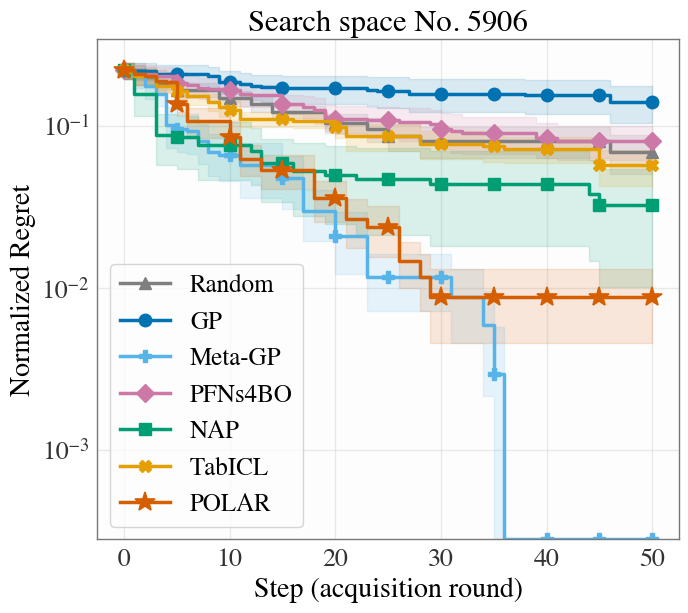

In [11]:
fig, ax = plot_hpob_curve_block(
    build_hpob_sources(SEARCH_SPACE_ID, metric="normalized_regret"),
    metric="normalized_regret",
    marker_every=5,
    save_path=REPO_ROOT / "figures" / f"hpob_normalized_regret_{SEARCH_SPACE_ID}.pdf",
)
plt.show()


## Multi-Space Summary

Average normalized regret and average ranking across multiple HPO-B search spaces.
Each search space contributes equally, so one task with a larger absolute scale does not dominate the average.


In [12]:
MULTI_SPACE_IDS = ["4796", "5859", "5860", "5906", "5889", "5527"]
MULTI_SPACE_PDF = REPO_ROOT / "figures" / "hpob_multi_space_regret_rank.pdf"

MULTI_SPACE_IDS


['4796', '5859', '5860', '5906', '5889', '5527']

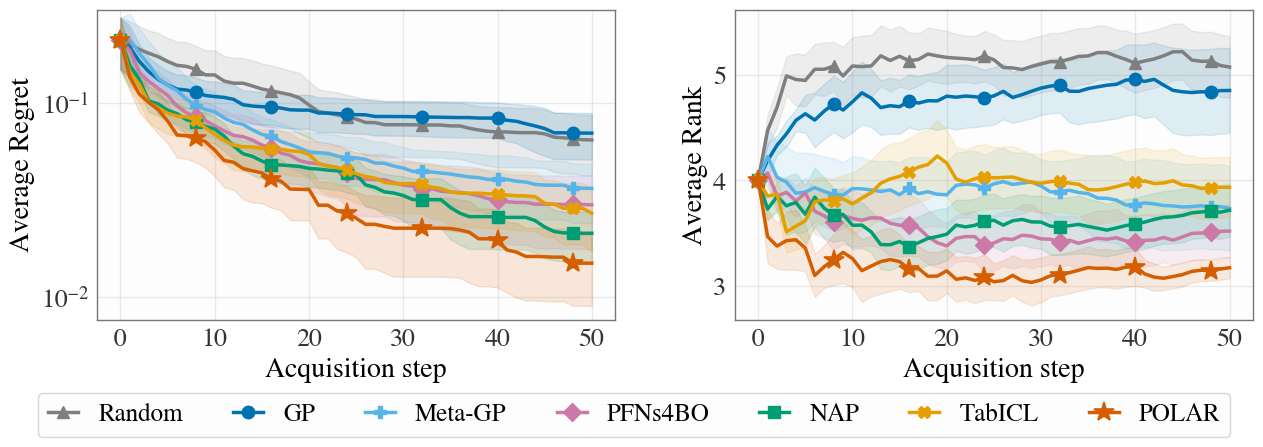

(['4796', '5859', '5860', '5906', '5889', '5527'],
 ['Random', 'GP', 'Meta-GP', 'PFNs4BO', 'NAP', 'TabICL', 'POLAR'])

In [13]:
fig, axes, summary = plot_hpob_multi_space_summary(
    MULTI_SPACE_IDS,
    build_hpob_sources,
    metric="normalized_regret",
    marker_every=8,
    save_path=MULTI_SPACE_PDF,
)
display(fig)
plt.close(fig)

summary["search_space_ids"], summary["methods"]


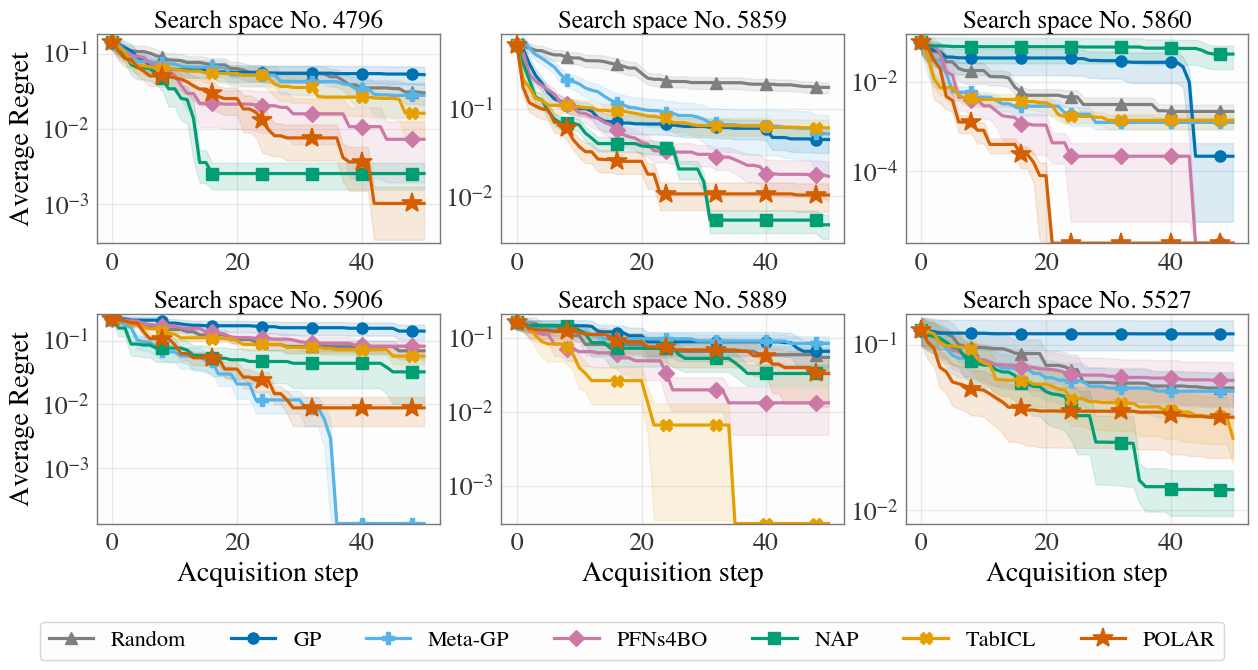

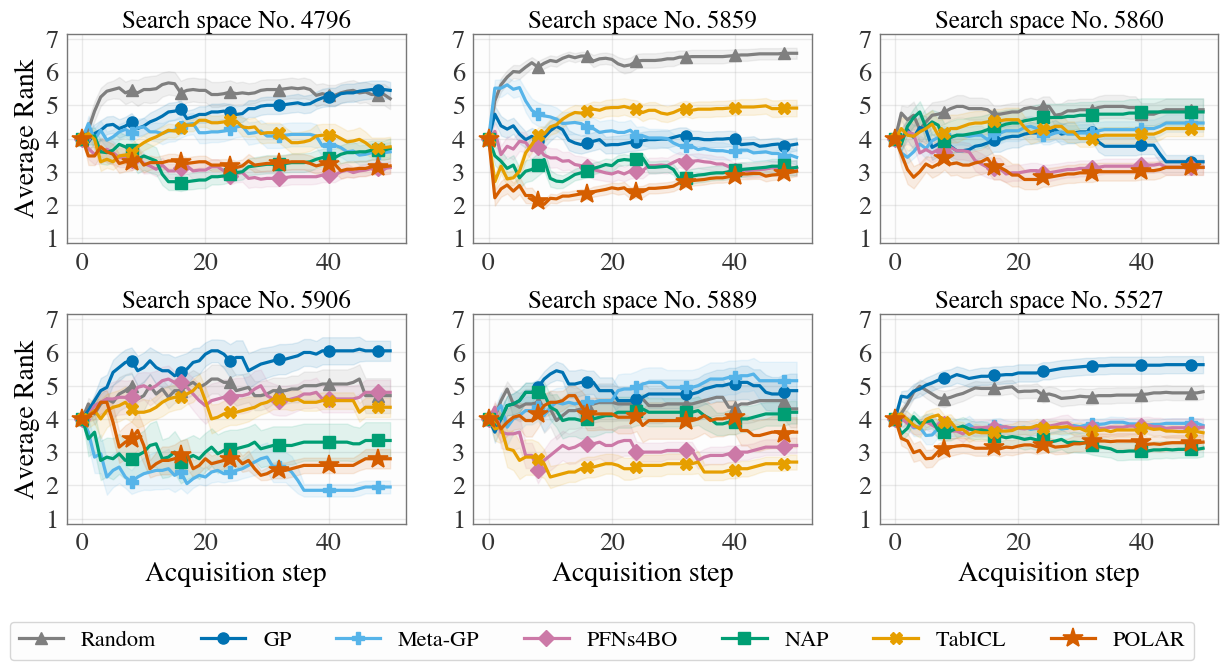

In [14]:
SEARCH_SPACE_IDS = ["4796", "5859", "5860", "5906", "5889", "5527"]

fig, axes = plot_hpob_search_space_regret_grid(
    SEARCH_SPACE_IDS,
    build_hpob_sources,
    marker_every=8,
    save_path=REPO_ROOT / "figures" / "hpob_regret.pdf",
)
display(fig)
plt.close(fig)

fig, axes = plot_hpob_search_space_rank_grid(
    SEARCH_SPACE_IDS,
    build_hpob_sources,
    marker_every=8,
    save_path=REPO_ROOT / "figures" / "hpob_rank.pdf",
)
display(fig)
plt.close(fig)
